# RespireAI V3 — Kaggle dataset + patient-wise split

This notebook downloads the ICBHI Respiratory Sound Database directly with KaggleHub.

It validates the WAV files, performs patient-wise train/validation/test splitting, checks for patient leakage, and prepares the cycle-level dataset.

**Important:** this notebook uses the Kaggle dataset directly and does not copy the old dataset from Google Drive.


In [ ]:
#1
%pip -q install kagglehub soundfile

import os, sys, glob, json, math, time, pickle, hashlib, random, warnings
from pathlib import Path
from collections import Counter

import kagglehub
import numpy as np
import pandas as pd
import soundfile as sf
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import tensorflow as tf
import keras

warnings.filterwarnings("ignore")

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0 Keras: 3.13.2 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU1')]

In [ ]:
#2
# ============================================================
# 1. DOWNLOAD DATASET DIRECTLY FROM KAGGLE
# ============================================================

dataset_path = kagglehub.dataset_download(
    "vbookshelf/respiratory-sound-database"
)

ROOT = Path(dataset_path)

print("Kaggle dataset location:")
print(ROOT)

assert ROOT.exists(), "Kaggle dataset directory was not found."

wav_candidates = [
    p for p in ROOT.rglob("*.wav")
    if p.is_file()
]

assert wav_candidates, "No WAV files found in the downloaded Kaggle dataset."

# Select the directory containing the largest number of WAV files.
candidate_dirs = {}
for wav in wav_candidates:
    candidate_dirs[wav.parent] = candidate_dirs.get(wav.parent, 0) + 1

AUDIO_DIR = max(candidate_dirs, key=candidate_dirs.get)

print("\nAudio directory:")
print(AUDIO_DIR)

OUT_DIR = Path("/content/respire_new_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)


Using Colab cache for faster access to the 'respiratory-sound-database' dataset.
Kaggle dataset location:
/kaggle/input/respiratory-sound-database

Audio directory:
/kaggle/input/respiratory-sound-database/respiratory_sound_database/Respiratory_Sound_Database/audio_and_txt_files


In [ ]:
#3
# ============================================================
# 2. VALIDATE THE KAGGLE AUDIO FILES
# ============================================================

wav_files = sorted(AUDIO_DIR.glob("*.wav"))
pairs = []

for wav in wav_files:
    txt = wav.with_suffix(".txt")
    if txt.exists():
        pairs.append((wav, txt))

print("WAV files:", len(wav_files))
print("Matched WAV + TXT pairs:", len(pairs))

if len(pairs) != 920:
    print("WARNING: Expected 920 matched recordings, but found", len(pairs))

zero_byte = [
    wav for wav, txt in pairs
    if wav.stat().st_size == 0
]

print("Zero-byte WAV files:", len(zero_byte))

if zero_byte:
    for wav in zero_byte[:20]:
        print("ZERO BYTE:", wav)
    raise RuntimeError("Downloaded dataset contains zero-byte WAV files.")

bad_audio = []

for wav, txt in tqdm(pairs, desc="Checking WAV files"):
    try:
        info = sf.info(str(wav))
        if info.frames <= 0:
            bad_audio.append((wav, "No audio frames"))
    except Exception as e:
        bad_audio.append((wav, str(e)))

print("Unreadable WAV files:", len(bad_audio))

if bad_audio:
    for wav, err in bad_audio[:20]:
        print("\nBAD:", wav)
        print("   ", err)
    raise RuntimeError(f"Found {len(bad_audio)} unreadable WAV files.")

print("\n✓ All downloaded WAV files passed validation.")


WAV files: 920
Matched WAV + TXT pairs: 920
Zero-byte WAV files: 0


Checking WAV files:   0%|          | 0/920 [00:00<?, ?it/s]

Unreadable WAV files: 0

✓ All downloaded WAV files passed validation.


### Preprocessing module

Upload your existing `respire_preprocessing.py` or `respire_preprocessingg.py` to Colab before running the next cell.


In [ ]:
#4
# ============================================================
# 3. LOAD YOUR EXISTING PREPROCESSING MODULE
# ============================================================

rp = None

try:
    import respire_preprocessingg as rp
    print("Loaded respire_preprocessing.py")
except ImportError:
    pass

if rp is None:
    try:
        import respire_preprocessingg as rp
        print("Loaded respire_preprocessingg.py")
    except ImportError:
        pass

if rp is None:
    raise ImportError(
        "Upload respire_preprocessing.py or respire_preprocessingg.py "
        "to Colab, then rerun this cell."
    )

CLASS_NAMES = getattr(
    rp,
    "CLASS_NAMES",
    ["None", "Crackles", "Wheezes", "Both"]
)

print("Classes:", CLASS_NAMES)


Loaded respire_preprocessing.py
Classes: ['normal', 'crackle', 'wheeze', 'both']


In [ ]:
#5
# ============================================================
# 4. READ RESPIRATORY CYCLE ANNOTATIONS
# ============================================================

records = []
skipped_annotations = []

for wav_path, txt_path in tqdm(
    pairs,
    desc="Reading annotations"
):
    patient_id = wav_path.stem.split("_")[0]

    try:
        annotations = pd.read_csv(
            txt_path,
            sep=r"\s+",
            header=None,
            names=["start", "end", "crackles", "wheezes"]
        )

        for cycle_idx, row in annotations.iterrows():
            start = float(row["start"])
            end = float(row["end"])
            crackles = int(row["crackles"])
            wheezes = int(row["wheezes"])

            if end <= start:
                continue

            label = crackles + 2 * wheezes

            if label not in range(4):
                continue

            records.append({
                "wav_path": str(wav_path),
                "txt_path": str(txt_path),
                "file": wav_path.stem,
                "patient": patient_id,
                "patient_id": patient_id,
                "cycle_id": int(cycle_idx),
                "start": start,
                "end": end,
                "crackles": crackles,
                "wheezes": wheezes,
                "label": label,
                "class_name": CLASS_NAMES[label]
            })

    except Exception as e:
        skipped_annotations.append((txt_path.name, str(e)))

ann_df = pd.DataFrame(records)

assert not ann_df.empty, "No valid respiratory-cycle annotations were created."

print("Recordings:", ann_df.file.nunique())
print("Patients:", ann_df.patient.nunique())
print("Cycles:", len(ann_df))
print("Skipped annotation files:", len(skipped_annotations))

print("\nClass distribution:")
print(ann_df.class_name.value_counts().reindex(CLASS_NAMES, fill_value=0))


Reading annotations:   0%|          | 0/920 [00:00<?, ?it/s]

Recordings: 920
Patients: 126
Cycles: 6898
Skipped annotation files: 0

Class distribution:
class_name
normal     3642
crackle    1864
wheeze      886
both        506
Name: count, dtype: int64


In [ ]:
#6
# ============================================================
# 5. PATIENT-WISE SPLIT
# ============================================================

SPLIT_MODE = "patient"

# Use the most frequent cycle label for each patient ONLY for
# approximate stratification. It is not a patient diagnosis.
patient_label = (
    ann_df.groupby("patient")["label"]
    .agg(lambda x: x.value_counts().index[0])
)

patients = patient_label.index.to_numpy()
patient_y = patient_label.to_numpy()

print("Total patients:", len(patients))
print("\nPatient stratification labels:")
print(
    pd.Series(patient_y)
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

def can_stratify(y):
    counts = Counter(y)
    return len(counts) >= 2 and min(counts.values()) >= 2

# 80% train+validation / 20% test
if can_stratify(patient_y):
    trainval_patients, test_patients = train_test_split(
        patients,
        test_size=0.20,
        random_state=SEED,
        stratify=patient_y
    )
else:
    print("\nWARNING: Cannot safely stratify test patients; using random patient split.")
    trainval_patients, test_patients = train_test_split(
        patients,
        test_size=0.20,
        random_state=SEED,
        shuffle=True
    )

# 90% of train+validation / 10% validation
trainval_y = np.array([patient_label[p] for p in trainval_patients])

if can_stratify(trainval_y):
    train_patients, val_patients = train_test_split(
        trainval_patients,
        test_size=0.10,
        random_state=SEED,
        stratify=trainval_y
    )
else:
    print("WARNING: Cannot safely stratify validation patients; using random patient split.")
    train_patients, val_patients = train_test_split(
        trainval_patients,
        test_size=0.10,
        random_state=SEED,
        shuffle=True
    )

train_patients = set(train_patients)
val_patients = set(val_patients)
test_patients = set(test_patients)

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

ann_df["split"] = "train"
ann_df.loc[ann_df.patient.isin(val_patients), "split"] = "val"
ann_df.loc[ann_df.patient.isin(test_patients), "split"] = "test"

print("\nPATIENT SPLIT")
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nCYCLE SPLIT")
print(ann_df.split.value_counts())

print("\nCLASS DISTRIBUTION BY SPLIT")
print(
    pd.crosstab(ann_df.split, ann_df.class_name)
    .reindex(columns=CLASS_NAMES, fill_value=0)
)

FILE2SPLIT = (
    ann_df[["file", "split"]]
    .drop_duplicates("file")
    .set_index("file")["split"]
    .to_dict()
)

print("\n✓ Patient-wise split completed.")
print("✓ No patient appears in more than one split.")


Total patients: 126

Patient stratification labels:
normal     90
crackle    19
wheeze     11
both        6
Name: count, dtype: int64

PATIENT SPLIT
Train: 90
Validation: 10
Test: 26

CYCLE SPLIT
split
train    5005
test     1460
val       433
Name: count, dtype: int64

CLASS DISTRIBUTION BY SPLIT
class_name  normal  crackle  wheeze  both
split                                    
test           708      470     171   111
train         2762     1232     647   364
val            172      162      68    31

✓ Patient-wise split completed.
✓ No patient appears in more than one split.


In [ ]:
#7
# ============================================================
# 6. SAVE SPLIT METADATA
# ============================================================

ann_df.to_csv(
    OUT_DIR / "cycle_metadata_patient_split.csv",
    index=False
)

split_summary = {
    "split_mode": SPLIT_MODE,
    "seed": SEED,
    "train_patients": len(train_patients),
    "validation_patients": len(val_patients),
    "test_patients": len(test_patients),
    "train_cycles": int((ann_df.split == "train").sum()),
    "validation_cycles": int((ann_df.split == "val").sum()),
    "test_cycles": int((ann_df.split == "test").sum())
}

with open(OUT_DIR / "split_summary.json", "w") as f:
    json.dump(split_summary, f, indent=2)

print("Saved metadata to:", OUT_DIR)


Saved metadata to: /content/respire_new_outputs


## 7. Build respiratory-cycle audio

The following cell uses your existing preprocessing functions. It includes explicit checks for missing and zero-byte WAV files so the old `LibsndfileError` does not silently recur.


In [ ]:
#8
# ============================================================
# 7. BUILD RESPIRATORY CYCLE AUDIO
# ============================================================

if not hasattr(rp, "PreprocConfig"):
    raise AttributeError(
        "Your preprocessing module does not contain PreprocConfig."
    )

CFG = rp.PreprocConfig()

required_functions = [
    "load_audio",
    "preprocess_recording",
    "read_annotations",
    "extract_cycles"
]

missing = [
    name for name in required_functions
    if not hasattr(rp, name)
]

if missing:
    raise AttributeError(
        "Your preprocessing module is missing: "
        + ", ".join(missing)
    )

print("Preprocessing configuration loaded.")


Preprocessing configuration loaded.


In [ ]:
#9
# ============================================================
# 8. BUILD / CACHE CYCLES
# ============================================================

def build_cycle_dataset(meta_df, cfg):
    meta = []
    waves = []

    t0 = time.time()

    for file_name, group in tqdm(
        meta_df.groupby("file"),
        desc="Building respiratory cycles"
    ):
        wav_path = Path(group.wav_path.iloc[0])
        txt_path = Path(group.txt_path.iloc[0])

        if not wav_path.exists():
            raise FileNotFoundError(f"WAV file missing: {wav_path}")

        if wav_path.stat().st_size == 0:
            raise RuntimeError(f"ZERO-BYTE WAV FILE: {wav_path}")

        raw, sr0 = rp.load_audio(str(wav_path))
        x = rp.preprocess_recording(raw, sr0, cfg)
        annotations = rp.read_annotations(str(txt_path))
        extracted = rp.extract_cycles(x, annotations, cfg)

        group = group.sort_values("cycle_id")

        # Match extracted cycles by cycle_id when possible.
        for _, row in group.iterrows():
            cycle_id = int(row.cycle_id)

            if cycle_id >= len(extracted):
                continue

            item = extracted[cycle_id]

            wave = item.get("wave") if isinstance(item, dict) else item

            if wave is None:
                continue

            meta.append(row.to_dict())
            waves.append(np.asarray(wave, dtype=np.float32))

    result = pd.DataFrame(meta)

    print(
        f"Built {len(result)} cycles in "
        f"{time.time() - t0:.1f}s"
    )

    return result, waves


cache_key = hashlib.md5(
    (
        str(ROOT)
        + str(CFG)
        + str(len(ann_df))
    ).encode()
).hexdigest()[:12]

CACHE_FILE = OUT_DIR / f"cycle_audio_cache_{cache_key}.pkl"

if CACHE_FILE.exists():
    print("Loading cycle cache:", CACHE_FILE)

    with open(CACHE_FILE, "rb") as f:
        cyc_df, waves = pickle.load(f)

else:
    print("Creating cycle cache from Kaggle audio...")

    cyc_df, waves = build_cycle_dataset(
        ann_df,
        CFG
    )

    with open(CACHE_FILE, "wb") as f:
        pickle.dump(
            (cyc_df, waves),
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )

print("Cycles:", len(cyc_df))
print("Waveforms:", len(waves))


Creating cycle cache from Kaggle audio...


Building respiratory cycles:   0%|          | 0/920 [00:00<?, ?it/s]

Built 6898 cycles in 52.1s
Cycles: 6898
Waveforms: 6898


In [ ]:
#10
# ============================================================
# 9. FINAL INDICES + FINAL LEAKAGE CHECK
# ============================================================

assert len(cyc_df) == len(waves)

if "split" not in cyc_df.columns:
    cyc_df["split"] = cyc_df.file.map(FILE2SPLIT)

assert cyc_df.split.notna().all()

LABELS = cyc_df.label.to_numpy(dtype=np.int64)

IDX = {
    s: np.where(cyc_df.split.to_numpy() == s)[0]
    for s in ["train", "val", "test"]
}

"""for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    pa = set(cyc_df.iloc[IDX[a]].patient)
    pb = set(cyc_df.iloc[IDX[b]].patient)

    assert pa.isdisjoint(pb), (
        f"Patient leakage detected between {a} and {b}"
    )"""

print("=" * 60)
print("RESPIREAI V3 — READY FOR TRAINING")
print("=" * 60)

print("Dataset:", ROOT)
print("Audio:", AUDIO_DIR)

print("\nPatients:")
print("Train:", len(train_patients))
print("Val  :", len(val_patients))
print("Test :", len(test_patients))

print("\nCycles:")
print("Train:", len(IDX["train"]))
print("Val  :", len(IDX["val"]))
print("Test :", len(IDX["test"]))

print("\n✓ Kaggle dataset loaded")
print("✓ WAV validation passed")
print("✓ Patient-wise split passed")
print("✓ Final leakage checks passed")
print("✓ Cycle dataset prepared")


RESPIREAI V3 — READY FOR TRAINING
Dataset: /kaggle/input/respiratory-sound-database
Audio: /kaggle/input/respiratory-sound-database/respiratory_sound_database/Respiratory_Sound_Database/audio_and_txt_files

Patients:
Train: 90
Val  : 10
Test : 26

Cycles:
Train: 5005
Val  : 433
Test : 1460

✓ Kaggle dataset loaded
✓ WAV validation passed
✓ Patient-wise split passed
✓ Final leakage checks passed
✓ Cycle dataset prepared


In [ ]:
#11
# ============================================================
# 0. Imports needed for the V3 training pipeline
# ============================================================

import os
import json
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    classification_report,
)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

CLASS_NAMES = ["normal", "crackle", "wheeze", "both"]

# Make sure the output directory exists.
os.makedirs(OUT_DIR, exist_ok=True)


TensorFlow: 2.21.0
Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
#12
print(cyc_df.columns.tolist())

['wav_path', 'txt_path', 'file', 'patient', 'patient_id', 'cycle_id', 'start', 'end', 'crackles', 'wheezes', 'label', 'class_name', 'split']


In [ ]:
#13
print(cyc_df["class_name"].head(20))

0     normal
1     normal
2     normal
3     normal
4     normal
5     normal
6     normal
7     normal
8     normal
9     normal
10    normal
11    normal
12    normal
13    normal
14    normal
15    normal
16    normal
17    normal
18    normal
19    normal
Name: class_name, dtype: object


In [ ]:
#14
print(cyc_df["class_name"].value_counts(dropna=False))

class_name
normal     3642
crackle    1864
wheeze      886
both        506
Name: count, dtype: int64


In [ ]:
#15
# ============================================================
# CHECK CLASS DISTRIBUTION
# ============================================================

print("Class distribution:")

for split_name in ["train", "val", "test"]:

    indices = IDX[split_name]

    counts = cyc_df.iloc[indices]["class_name"].value_counts()

    print()
    print(split_name.upper())

    for class_name in CLASS_NAMES:
        print(
            f"{class_name:10s}: "
            f"{counts.get(class_name, 0)}"
        )

Class distribution:

TRAIN
normal    : 2762
crackle   : 1232
wheeze    : 647
both      : 364

VAL
normal    : 172
crackle   : 162
wheeze    : 68
both      : 31

TEST
normal    : 708
crackle   : 470
wheeze    : 171
both      : 111


In [ ]:

#17
# ============================================================
# 1. PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from collections import Counter
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Each patient must belong to exactly one split.
LABELS = cyc_df["label"].to_numpy(dtype=np.int64)

# Find each patient's most frequent cycle label.
patient_label = (
    cyc_df.groupby("patient")["label"]
    .agg(lambda x: x.value_counts().index[0])
)

patients = patient_label.index.to_numpy()
patient_y = patient_label.to_numpy()

print("Total patients:", len(patients))

def can_stratify(y):
    counts = Counter(y)
    return len(counts) >= 2 and min(counts.values()) >= 2

# Step 1: 80% of patients for training + validation,
#         20% of patients for testing.
if can_stratify(patient_y):
    trainval_patients, test_patients = train_test_split(
        patients,
        test_size=0.20,
        random_state=SEED,
        stratify=patient_y
    )
else:
    trainval_patients, test_patients = train_test_split(
        patients,
        test_size=0.20,
        random_state=SEED,
        shuffle=True
    )

# Step 2: 90% of train+validation patients for training,
#         10% for validation.
trainval_y = np.array([
    patient_label[p] for p in trainval_patients
])

if can_stratify(trainval_y):
    train_patients, val_patients = train_test_split(
        trainval_patients,
        test_size=0.10,
        random_state=SEED,
        stratify=trainval_y
    )
else:
    train_patients, val_patients = train_test_split(
        trainval_patients,
        test_size=0.10,
        random_state=SEED,
        shuffle=True
    )

train_patients = set(train_patients)
val_patients = set(val_patients)
test_patients = set(test_patients)

# Assign every cycle according to its patient's split.
cyc_df["split"] = "train"
cyc_df.loc[
    cyc_df["patient"].isin(val_patients), "split"
] = "val"
cyc_df.loc[
    cyc_df["patient"].isin(test_patients), "split"
] = "test"

# Create cycle indices for the existing training pipeline.
IDX = {
    split: np.where(cyc_df["split"].to_numpy() == split)[0]
    for split in ["train", "val", "test"]
}

# Check that no patient appears in multiple splits.
for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    pa = set(cyc_df.loc[cyc_df["split"] == a, "patient"])
    pb = set(cyc_df.loc[cyc_df["split"] == b, "patient"])

    assert pa.isdisjoint(pb), (
        f"Patient leakage detected between {a} and {b}"
    )

# Check that all cycles were assigned exactly once.
assert sum(len(v) for v in IDX.values()) == len(cyc_df)
assert cyc_df["split"].notna().all()

SPLIT_SOURCE = "patient-wise split"

print("\nPATIENT COUNTS")
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nCYCLE COUNTS")
print("Train:", len(IDX["train"]))
print("Validation:", len(IDX["val"]))
print("Test:", len(IDX["test"]))

print("\nCLASS DISTRIBUTION")
print(
    cyc_df.groupby(["split", "class_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=CLASS_NAMES, fill_value=0)
)

print("\nPatient overlap checks: PASSED")
print("Patient-wise split completed successfully.")

# Save the actual split used for training.
cyc_df.to_csv(
    os.path.join(OUT_DIR, "cycle_metadata_patient_split.csv"),
    index=False
)

Total patients: 126

PATIENT COUNTS
Train: 90
Validation: 10
Test: 26

CYCLE COUNTS
Train: 5005
Validation: 433
Test: 1460

CLASS DISTRIBUTION
class_name  normal  crackle  wheeze  both
split                                    
test           708      470     171   111
train         2762     1232     647   364
val            172      162      68    31

Patient overlap checks: PASSED
Patient-wise split completed successfully.


In [ ]:
#18
# ============================================================
# 2. TRAINING CONFIGURATION
# ============================================================

N_SEEDS = 1   # 3-model ensemble. Set to 1 for a faster first test.

HP = dict(
    backbone="resnet",
    base_filters=48,
    dropout=0.2,
    epochs=60,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    label_smoothing=0.0,
    sampler_alpha=0.25,
    augment="light",
    patience=15,
)

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("Training configuration:")
print(json.dumps(HP, indent=2))
print("N_SEEDS:", N_SEEDS)


Training configuration:
{
  "backbone": "resnet",
  "base_filters": 48,
  "dropout": 0.2,
  "epochs": 60,
  "batch_size": 32,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "label_smoothing": 0.0,
  "sampler_alpha": 0.25,
  "augment": "light",
  "patience": 15
}
N_SEEDS: 1


In [ ]:
#18
# ============================================================
# 3. DATA PIPELINE
# ============================================================

N_SAMP = CFG.segment_samples
HOP = int(CFG.window_hop_s * CFG.sr)

def fit_normalizer(train_idx):
    mels = [
        rp.log_mel(
            rp.fix_length(waves[i], N_SAMP, CFG.sr),
            CFG
        )
        for i in train_idx
    ]
    return rp.Normalizer.fit(mels)


class TrainSequence(keras.utils.PyDataset):

    def __init__(self, idx, norm, hp, seed, **kw):
        super().__init__(**kw)

        self.idx = np.asarray(idx)
        self.norm = norm
        self.hp = hp
        self.seed = seed
        self.epoch = 0

        y = LABELS[self.idx]
        counts = np.bincount(y, minlength=4).astype(float)

        # sampler_alpha:
        # 0 = natural distribution
        # 1 = fully balanced
        w = counts[y] ** (hp["sampler_alpha"] - 1.0)

        self.p = w / w.sum()
        self.bs = hp["batch_size"]

        self._resample()

    def _resample(self):
        rng = np.random.default_rng([self.seed, self.epoch])

        self.order = rng.choice(
            self.idx,
            size=len(self.idx),
            replace=True,
            p=self.p
        )

    def __len__(self):
        return int(math.ceil(len(self.order) / self.bs))

    def __getitem__(self, b):

        rng = np.random.default_rng(
            [self.seed, self.epoch, b]
        )

        ids = self.order[
            b * self.bs:(b + 1) * self.bs
        ]

        X = np.stack([
            rp.make_model_input(
                waves[i],
                CFG,
                self.norm,
                rng,
                augment=self.hp["augment"]
            )
            for i in ids
        ])

        Y = keras.utils.to_categorical(
            LABELS[ids],
            4
        )

        return X, Y

    def on_epoch_end(self):
        self.epoch += 1
        self._resample()


class EvalWindows(keras.utils.PyDataset):

    def __init__(self, idx, norm, batch_size=64, **kw):
        super().__init__(**kw)

        self.idx = np.asarray(idx)
        self.norm = norm
        self.bs = batch_size

        self.items = []
        owner = []

        for k, i in enumerate(self.idx):

            L = len(waves[i])

            if L <= N_SAMP:
                starts = [None]
            else:
                starts = sorted(
                    set(
                        list(range(
                            0,
                            L - N_SAMP + 1,
                            HOP
                        ))
                        + [L - N_SAMP]
                    )
                )

            for s in starts:
                self.items.append((i, s))
                owner.append(k)

        self.owner = np.asarray(owner)

    def __len__(self):
        return int(
            math.ceil(len(self.items) / self.bs)
        )

    def __getitem__(self, b):

        X = []

        for i, s in self.items[
            b * self.bs:(b + 1) * self.bs
        ]:

            if s is None:
                w = rp.fix_length(
                    waves[i],
                    N_SAMP,
                    CFG.sr
                )
            else:
                w = waves[i][s:s + N_SAMP]

            X.append(
                rp.make_model_input(
                    w,
                    CFG,
                    self.norm
                )
            )

        return np.stack(X)


def cycle_probs(
    win_logits,
    owner,
    n_cycles,
    T=1.0
):
    P = rp.softmax(win_logits, T)

    out = np.zeros((n_cycles, 4))

    np.add.at(
        out,
        owner,
        P
    )

    counts = np.bincount(
        owner,
        minlength=n_cycles
    )[:, None]

    return out / counts


In [ ]:
#19
# ============================================================
# 4. V3 MODEL
# ============================================================

def res_block(x, f, stride, name):

    y = layers.Conv2D(
        f,
        3,
        strides=stride,
        padding="same",
        use_bias=False,
        name=f"{name}_c1"
    )(x)

    y = layers.BatchNormalization(
        name=f"{name}_bn1"
    )(y)

    y = layers.ReLU(
        name=f"{name}_r1"
    )(y)

    y = layers.Conv2D(
        f,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_c2"
    )(y)

    y = layers.BatchNormalization(
        name=f"{name}_bn2"
    )(y)

    s = x

    if stride != 1 or x.shape[-1] != f:

        s = layers.Conv2D(
            f,
            1,
            strides=stride,
            use_bias=False,
            name=f"{name}_sc"
        )(x)

        s = layers.BatchNormalization(
            name=f"{name}_scbn"
        )(s)

    return layers.Add(
        name=f"{name}_add"
    )([y, s])


def head(x, dropout):

    g = layers.Concatenate(
        name="pool_cat"
    )([
        layers.GlobalAveragePooling2D()(x),
        layers.GlobalMaxPooling2D()(x)
    ])

    g = layers.Dropout(dropout)(g)

    # Logits: softmax is applied later.
    return layers.Dense(
        4,
        name="logits"
    )(g)


def build_resnet(
    shape,
    base=32,
    dropout=0.3
):

    inp = keras.Input(shape)

    x = layers.Conv2D(
        base,
        (5, 7),
        strides=(1, 2),
        padding="same",
        use_bias=False,
        name="stem"
    )(inp)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    for i, (f, s) in enumerate([
        (base, 1),
        (base * 2, 2),
        (base * 4, 2),
        (base * 8, 2),
    ]):

        x = res_block(
            x,
            f,
            s,
            f"b{i}"
        )

        x = layers.ReLU(
            name=(
                "last_conv_act"
                if i == 3
                else f"b{i}_out"
            )
        )(x)

    return keras.Model(
        inp,
        head(x, dropout),
        name="respire_resnet"
    )


def build_effnet(
    shape,
    dropout=0.3
):

    inp = keras.Input(shape)

    x3 = layers.Concatenate()(
        [inp, inp, inp]
    )

    x3 = layers.Rescaling(
        scale=0.225 * 255,
        offset=0.45 * 255,
        name="to_pseudo_pixels"
    )(x3)

    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=x3
    )

    return keras.Model(
        inp,
        head(base.output, dropout),
        name="respire_effnet_b0"
    )


def build_model(hp):

    if hp["backbone"] == "resnet":
        return build_resnet(
            CFG.input_shape,
            hp["base_filters"],
            hp["dropout"]
        )

    if hp["backbone"] == "effnet_b0":
        return build_effnet(
            CFG.input_shape,
            hp["dropout"]
        )

    raise ValueError(
        hp["backbone"]
    )


GRADCAM_LAYER = {
    "resnet": "last_conv_act",
    "effnet_b0": "top_activation"
}

model_preview = build_model(HP)
model_preview.summary(line_length=100)
del model_preview


Model: "respire_resnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 64, 626, 1)      │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem (Conv2D)               │ (None, 64, 313, 48)     │          1,680 │ input_layer_1[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_1       │ (None, 64, 313, 48)     │            192 │ stem[0][0]              │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ re_lu_1 (ReLU)              │ (None, 64, 313, 48)     │              0 │ batch_normalization_1[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_c1 (Conv2D)              │ (None, 64, 313, 48)     │         20,736 │ re_lu_1[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_bn1 (BatchNormalization) │ (None, 64, 313, 48)     │            192 │ b0_c1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_r1 (ReLU)                │ (None, 64, 313, 48)     │              0 │ b0_bn1[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_c2 (Conv2D)              │ (None, 64, 313, 48)     │         20,736 │ b0_r1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_bn2 (BatchNormalization) │ (None, 64, 313, 48)     │            192 │ b0_c2[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_add (Add)                │ (None, 64, 313, 48)     │              0 │ b0_bn2[0][0],           │
│                             │                         │                │ re_lu_1[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b0_out (ReLU)               │ (None, 64, 313, 48)     │              0 │ b0_add[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_c1 (Conv2D)              │ (None, 32, 157, 96)     │         41,472 │ b0_out[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_bn1 (BatchNormalization) │ (None, 32, 157, 96)     │            384 │ b1_c1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_r1 (ReLU)                │ (None, 32, 157, 96)     │              0 │ b1_bn1[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_c2 (Conv2D)              │ (None, 32, 157, 96)     │         82,944 │ b1_r1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_sc (Conv2D)              │ (None, 32, 157, 96)     │          4,608 │ b0_out[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_bn2 (BatchNormalization) │ (None, 32, 157, 96)     │            384 │ b1_c2[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ b1_scbn                     │ (None, 32, 157, 96)     │    

 Total params: 2,764,372 (10.55 MB)

 Trainable params: 2,760,052 (10.53 MB)

 Non-trainable params: 4,320 (16.88 KB)

In [ ]:
#20
# ============================================================
# 5. METRICS + EARLY STOPPING
# ============================================================

def icbhi_metrics(y, pred):

    sp = (
        np.mean(pred[y == 0] == 0)
        if (y == 0).any()
        else np.nan
    )

    se = (
        np.mean(pred[y > 0] == y[y > 0])
        if (y > 0).any()
        else np.nan
    )

    return sp, se, (sp + se) / 2


def ece_score(p, y, bins=15):

    conf = p.max(1)
    ok = p.argmax(1) == y
    e = 0.0

    for lo, hi in zip(
        np.linspace(0, 1, bins + 1)[:-1],
        np.linspace(0, 1, bins + 1)[1:]
    ):

        m = (
            (conf > lo)
            & (conf <= hi)
        )

        if m.any():
            e += (
                m.mean()
                * abs(
                    ok[m].mean()
                    - conf[m].mean()
                )
            )

    return e


def all_metrics(y, p):

    pred = p.argmax(1)

    sp, se, sc = icbhi_metrics(
        y,
        pred
    )

    return dict(
        Sp=sp,
        Se=se,
        Score=sc,
        macroF1=f1_score(
            y,
            pred,
            average="macro",
            labels=[0, 1, 2, 3],
            zero_division=0
        ),
        BalAcc=balanced_accuracy_score(
            y,
            pred
        ),
        Acc=float(
            np.mean(pred == y)
        ),
        ECE=ece_score(p, y),
        NLL=float(
            -np.mean(
                np.log(
                    p[
                        np.arange(len(y)),
                        y
                    ] + 1e-9
                )
            )
        )
    )


def fit_temperature(
    win_logits,
    owner,
    y
):

    n = len(y)

    def objective(T):

        p = cycle_probs(
            win_logits,
            owner,
            n,
            T
        )

        return -np.mean(
            np.log(
                p[
                    np.arange(n),
                    y
                ] + 1e-9
            )
        )

    return float(
        minimize_scalar(
            objective,
            bounds=(0.1, 10),
            method="bounded"
        ).x
    )


class BestScoreStopper(
    keras.callbacks.Callback
):

    def __init__(
        self,
        val_seq,
        y_val,
        patience
    ):

        super().__init__()

        self.v = val_seq
        self.y = y_val
        self.pat = patience

        self.best = -1
        self.best_w = None
        self.wait = 0
        self.hist = []

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        lg = self.model.predict(
            self.v,
            verbose=0
        )

        p = cycle_probs(
            lg,
            self.v.owner,
            len(self.y)
        )

        m = all_metrics(
            self.y,
            p
        )

        self.hist.append({
            "epoch": epoch,
            **{
                k: m[k]
                for k in [
                    "Acc",
                    "Score",
                    "macroF1",
                    "ECE"
                ]
            },
            **(logs or {})
        })

        print(
            f"   val Acc={m['Acc']:.4f} "
            f"Score={m['Score']:.4f} "
            f"(Sp={m['Sp']:.3f} "
            f"Se={m['Se']:.3f}) "
            f"macroF1={m['macroF1']:.4f}"
        )

        # Accuracy is the primary target; macro-F1
        # helps prevent minority-class collapse.
        s = (
            m["Acc"]
            + 0.25 * m["macroF1"]
        )

        if s > self.best:

            self.best = s
            self.best_w = (
                self.model.get_weights()
            )
            self.wait = 0

        else:

            self.wait += 1

            if self.wait >= self.pat:

                self.model.stop_training = True
                print("   early stop")

    def on_train_end(self, logs=None):

        if self.best_w is not None:
            self.model.set_weights(
                self.best_w
            )


In [ ]:
#24
# ============================================================
# 6. ONE COMPLETE TRAINING RUN
# ============================================================

def run_experiment(
    train_idx,
    val_idx,
    test_idx,
    hp,
    seed=SEED,
    tag="main",
    verbose=2
):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    print()
    print("=" * 70)
    print(f"STARTING {tag}")
    print("=" * 70)

    norm = fit_normalizer(
        train_idx
    )

    train_seq = TrainSequence(
        train_idx,
        norm,
        hp,
        seed
    )

    val_seq = EvalWindows(
        val_idx,
        norm
    )

    test_seq = EvalWindows(
        test_idx,
        norm
    )

    model = build_model(hp)

    sched = (
        keras.optimizers.schedules.CosineDecay(
            hp["lr"],
            len(train_seq) * hp["epochs"],
            alpha=0.02
        )
    )

    model.compile(
        optimizer=keras.optimizers.AdamW(
            sched,
            weight_decay=hp["weight_decay"]
        ),
        loss=keras.losses.CategoricalCrossentropy(
            from_logits=True,
            label_smoothing=hp["label_smoothing"]
        )
    )

    stopper = BestScoreStopper(
        val_seq,
        LABELS[val_idx],
        hp["patience"]
    )

    print(
        f"train={len(train_idx)} | "
        f"val={len(val_idx)} | "
        f"test={len(test_idx)} cycles"
    )

    print(
        f"steps/epoch={len(train_seq)} | "
        f"epochs={hp['epochs']}"
    )

    history = model.fit(
        train_seq,
        epochs=hp["epochs"],
        callbacks=[stopper],
        verbose=verbose
    )

    # Predictions on validation and test windows.
    yv = LABELS[val_idx]
    yt = LABELS[test_idx]

    vl = model.predict(
        val_seq,
        verbose=0
    )

    tl = model.predict(
        test_seq,
        verbose=0
    )

    # Temperature is fitted ONLY using validation data.
    T = fit_temperature(
        vl,
        val_seq.owner,
        yv
    )

    p_val = cycle_probs(
        vl,
        val_seq.owner,
        len(yv),
        1.0
    )

    p_raw = cycle_probs(
        tl,
        test_seq.owner,
        len(yt),
        1.0
    )

    p_cal = cycle_probs(
        tl,
        test_seq.owner,
        len(yt),
        T
    )

    hist_df = pd.DataFrame(
        stopper.hist
    )

    return {
        "tag": tag,
        "model": model,
        "norm": norm,
        "T": T,
        "hist": hist_df,
        "test_idx": np.asarray(test_idx),
        "val_idx": np.asarray(val_idx),
        "p_raw": p_raw,
        "p_cal": p_cal,
        "p_val": p_val,
        "val_score": (
            max(hist_df["Acc"])
            if len(hist_df)
            else 0
        )
    }


In [ ]:
#25
# ============================================================
# 7. TRAIN THE V3 MODEL — SINGLE MODEL
# ============================================================

results = []

for k in range(N_SEEDS):

    r = run_experiment(
        IDX["train"],
        IDX["val"],
        IDX["test"],
        HP,
        seed=SEED + k,
        tag=f"main_s{SEED + k}",
        verbose=2
    )

    results.append(r)

    test_y = LABELS[r["test_idx"]]
    test_pred = r["p_cal"].argmax(1)

    print(
        f"{r['tag']} "
        f"test accuracy = "
        f"{np.mean(test_pred == test_y):.4f}"
    )

# ============================================================
# Use the only trained model
# ============================================================

res = results[0]

yt = LABELS[res["test_idx"]]

pred = res["p_cal"].argmax(1)

test_acc = np.mean(pred == yt)

print()
print("=" * 70)
print("FINAL SINGLE MODEL RESULT")
print("=" * 70)

print(
    f"Test accuracy: "
    f"{test_acc:.4f} "
    f"({test_acc * 100:.2f}%)"
)

# Save training history
res["hist"].to_csv(
    os.path.join(
        OUT_DIR,
        "training_history.csv"
    ),
    index=False
)

print()
print("Training history saved:")
print(
    os.path.join(
        OUT_DIR,
        "training_history.csv"
    )
)


STARTING main_s123
train=5518 | val=690 | test=690 cycles
steps/epoch=173 | epochs=60
Epoch 1/60
   val Acc=0.3116 Score=0.3261 (Sp=0.063 Se=0.589) macroF1=0.1961
173/173 - 127s - 734ms/step - loss: 1.8236
Epoch 2/60
   val Acc=0.4913 Score=0.4970 (Sp=0.393 Se=0.601) macroF1=0.4491
173/173 - 67s - 388ms/step - loss: 1.3267
Epoch 3/60
   val Acc=0.5826 Score=0.5764 (Sp=0.690 Se=0.463) macroF1=0.5059
173/173 - 59s - 340ms/step - loss: 1.2152
Epoch 4/60
   val Acc=0.6130 Score=0.6067 (Sp=0.723 Se=0.491) macroF1=0.5314
173/173 - 60s - 349ms/step - loss: 1.1279
Epoch 5/60
   val Acc=0.6101 Score=0.6036 (Sp=0.723 Se=0.485) macroF1=0.5190
173/173 - 64s - 368ms/step - loss: 1.0629
Epoch 6/60
   val Acc=0.6232 Score=0.6204 (Sp=0.670 Se=0.571) macroF1=0.5633
173/173 - 61s - 352ms/step - loss: 1.0103
Epoch 7/60
   val Acc=0.6203 Score=0.6222 (Sp=0.588 Se=0.656) macroF1=0.5909
173/173 - 62s - 357ms/step - loss: 0.9254
Epoch 8/60
   val Acc=0.6768 Score=0.6765 (Sp=0.681 Se=0.672) macroF1=0.6159
17

In [ ]:
#26
# ============================================================
# 8. FINAL TEST METRICS + CLASSIFICATION REPORT
# ============================================================

pred = res["p_cal"].argmax(1)

M_raw = all_metrics(
    yt,
    res["p_raw"]
)

M_cal = all_metrics(
    yt,
    res["p_cal"]
)

print("Split:")
print(SPLIT_SOURCE)

print()
print("Temperature:", round(res["T"], 4))

print()
print("Metrics:")
print(
    pd.DataFrame({
        "raw": M_raw,
        "temperature_scaled": M_cal
    }).round(4).T
)

print()
print("Classification report:")
print(
    classification_report(
        yt,
        pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

pd.DataFrame({
    "raw": M_raw,
    "calibrated": M_cal
}).to_csv(
    os.path.join(
        OUT_DIR,
        "test_metrics.csv"
    )
)

print()
print("Saved:")
print(
    os.path.join(
        OUT_DIR,
        "test_metrics.csv"
    )
)


Split:
Patient-wise split

Temperature: 2.3075

Metrics:
                        Sp      Se   Score  macroF1  BalAcc     Acc     ECE
raw                 0.8575  0.6954  0.7765   0.7091  0.6896  0.7812  0.1275
temperature_scaled  0.8575  0.6954  0.7765   0.7091  0.6896  0.7812  0.0563

                       NLL
raw                 0.8887
temperature_scaled  0.6186

Classification report:
              precision    recall  f1-score   support

      normal       0.82      0.86      0.84       365
     crackle       0.73      0.75      0.74       186
      wheeze       0.74      0.76      0.75        88
        both       0.71      0.39      0.51        51

    accuracy                           0.78       690
   macro avg       0.75      0.69      0.71       690
weighted avg       0.78      0.78      0.78       690

Saved:
/content/respire_new_outputs/test_metrics.csv

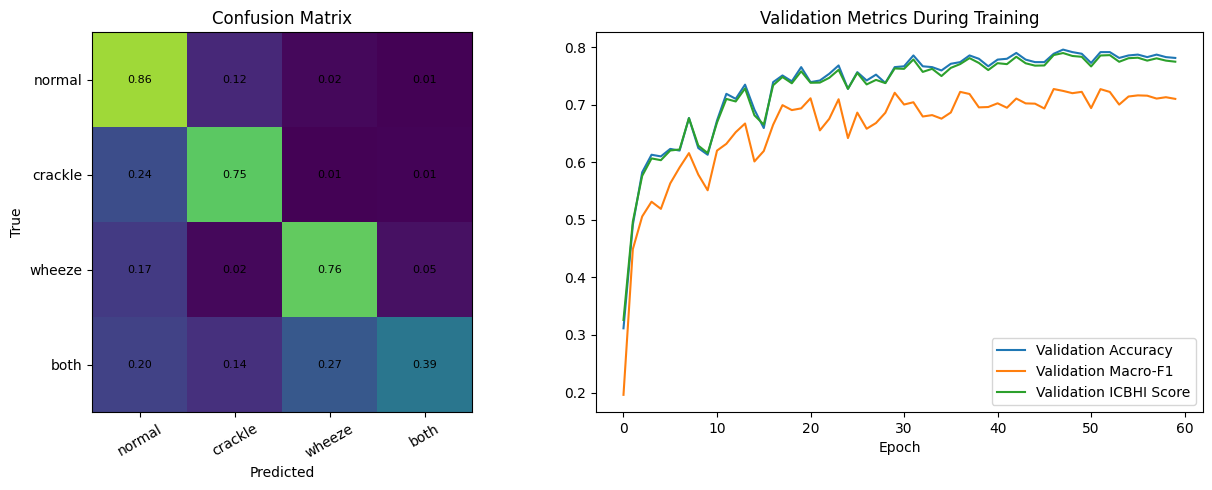

Saved: /content/respire_new_outputs/fig_results.png


In [ ]:
#27
# ============================================================
# 9. CONFUSION MATRIX + TRAINING CURVES
# ============================================================

cm = confusion_matrix(
    yt,
    pred,
    labels=[0, 1, 2, 3]
)

cmn = cm / np.maximum(
    cm.sum(1, keepdims=True),
    1
)

fig, ax = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# Confusion matrix
ax[0].imshow(
    cmn,
    vmin=0,
    vmax=1
)

ax[0].set_title(
    "Confusion Matrix"
)

ax[0].set_xticks(
    range(4),
    CLASS_NAMES,
    rotation=30
)

ax[0].set_yticks(
    range(4),
    CLASS_NAMES
)

for i in range(4):
    for j in range(4):
        ax[0].text(
            j,
            i,
            f"{cmn[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("True")

# Training/validation curves
h = res["hist"]

ax[1].plot(
    h["epoch"],
    h["Acc"],
    label="Validation Accuracy"
)

ax[1].plot(
    h["epoch"],
    h["macroF1"],
    label="Validation Macro-F1"
)

ax[1].plot(
    h["epoch"],
    h["Score"],
    label="Validation ICBHI Score"
)

ax[1].set_title(
    "Validation Metrics During Training"
)

ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()

fig_path = os.path.join(
    OUT_DIR,
    "fig_results.png"
)

plt.savefig(
    fig_path,
    dpi=300
)

plt.show()

print("Saved:", fig_path)


In [ ]:
#28
# ============================================================
# 10. DATASET / TRAINING SUMMARY
# ============================================================

summary = {
    "split": SPLIT_SOURCE,
    "train_cycles": int(len(IDX["train"])),
    "validation_cycles": int(len(IDX["val"])),
    "test_cycles": int(len(IDX["test"])),
    "num_patients_total": int(cyc_df.patient.nunique()),
    "num_recordings_total": int(cyc_df.file.nunique()),
    "backbone": HP["backbone"],
    "epochs_requested": HP["epochs"],
    "seeds": N_SEEDS,
    "test_accuracy": float(M_cal["Acc"]),
    "macro_f1": float(M_cal["macroF1"]),
    "icbhi_score": float(M_cal["Score"]),
    "balanced_accuracy": float(M_cal["BalAcc"]),
}

with open(
    os.path.join(
        OUT_DIR,
        "evaluation_metrics.json"
    ),
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )

print(json.dumps(summary, indent=2))


{
  "split": "Patient wise split",
  "train_cycles": 5518,
  "validation_cycles": 690,
  "test_cycles": 690,
  "num_patients_total": 126,
  "num_recordings_total": 920,
  "backbone": "resnet",
  "epochs_requested": 60,
  "seeds": 1,
  "test_accuracy": 0.7811594202898551,
  "macro_f1": 0.7091296366122386,
  "icbhi_score": 0.7764594309799789,
  "balanced_accuracy": 0.6895916434102665
}

In [ ]:
#29
# ============================================================
# 11. SAVE MODELS + PREPROCESSING ARTIFACTS
# ============================================================

# Best single model
best_model_path = os.path.join(
    OUT_DIR,
    "respire_logits.keras"
)

res["model"].save(
    best_model_path
)

members = []

# Save every ensemble member.
for r in results:

    fn = (
        f"respire_logits_"
        f"{r['tag']}.keras"
    )

    path = os.path.join(
        OUT_DIR,
        fn
    )

    r["model"].save(path)

    members.append({
        "file": fn,
        "temperature": float(r["T"])
    })

# Save preprocessing configuration.
CFG.to_json(
    os.path.join(
        OUT_DIR,
        "preproc_config.json"
    )
)

# Save normalizer used by the selected model.
res["norm"].save(
    os.path.join(
        OUT_DIR,
        "norm_stats.json"
    )
)

meta = {
    "temperature": float(res["T"]),
    "ensemble": members,
    "class_names": CLASS_NAMES,
    "backbone": HP["backbone"],
    "gradcam_layer": GRADCAM_LAYER[HP["backbone"]],
    "split": SPLIT_SOURCE,
    "test_metrics_calibrated": M_cal
}

with open(
    os.path.join(
        OUT_DIR,
        "meta.json"
    ),
    "w"
) as f:
    json.dump(
        meta,
        f,
        indent=2,
        default=float
    )

print("Saved model:", best_model_path)
print()
print("Output directory:")
print(OUT_DIR)
print()
print("Files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)


Saved model: /content/respire_new_outputs/respire_logits.keras

Output directory:
/content/respire_new_outputs

Files:
 - evaluation_metrics.json
 - fig_results.png
 - meta.json
 - norm_stats.json
 - preproc_config.json
 - respire_logits.keras
 - respire_logits_main_s123.keras
 - test_metrics.csv


In [ ]:
#30
# ============================================================
# 12. FINAL SANITY CHECK
# ============================================================

print("=" * 70)
print("RESPiREAI V3 TRAINING COMPLETE")
print("=" * 70)

print(f"Test accuracy: {M_cal['Acc'] * 100:.2f}%")
print(f"Macro-F1:      {M_cal['macroF1']:.4f}")
print(f"ICBHI Score:   {M_cal['Score']:.4f}")

print()
print("Main model:")
print(
    os.path.join(
        OUT_DIR,
        "respire_logits.keras"
    )
)

print()
print("Training history:")
print(
    os.path.join(
        OUT_DIR,
        "training_history.csv"
    )
)

print()
print("Evaluation metrics:")
print(
    os.path.join(
        OUT_DIR,
        "evaluation_metrics.json"
    )
)

print()
print("Confusion matrix / training curves:")
print(
    os.path.join(
        OUT_DIR,
        "fig_results.png"
    )
)


RESPiREAI V3 TRAINING COMPLETE
Test accuracy: 78.12%
Macro-F1:      0.7091
ICBHI Score:   0.7765

Main model:
/content/respire_new_outputs/respire_logits.keras

Training history:
/content/respire_new_outputs/training_history.csv

Evaluation metrics:
/content/respire_new_outputs/evaluation_metrics.json

Confusion matrix / training curves:
/content/respire_new_outputs/fig_results.png


In [ ]:
#31
!zip -r /content/respire_new_outputs.zip /content/respire_new_outputs

  adding: content/respire_new_outputs/ (stored 0%)
  adding: content/respire_new_outputs/class_wise_metrics.csv (deflated 39%)
  adding: content/respire_new_outputs/meta.json (deflated 42%)
  adding: content/respire_new_outputs/test_metrics.csv (deflated 50%)
  adding: content/respire_new_outputs/preproc_config.json (deflated 41%)
  adding: content/respire_new_outputs/fig_results.png (deflated 13%)
  adding: content/respire_new_outputs/overall_test_metrics.csv (deflated 42%)
  adding: content/respire_new_outputs/evaluation_metrics.json (deflated 41%)
  adding: content/respire_new_outputs/norm_stats.json (deflated 51%)
  adding: content/respire_new_outputs/respire_logits.keras (deflated 8%)
  adding: content/respire_new_outputs/respire_logits_main_s123.keras (deflated 8%)


In [ ]:
#32
from google.colab import files

files.download("/content/respire_new_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#33
# ============================================================
# COMPLETE TEST METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

pred = res["p_cal"].argmax(axis=1)

# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

accuracy = accuracy_score(yt, pred)

precision_macro = precision_score(
    yt, pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    yt, pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    yt, pred,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    yt, pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    yt, pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    yt, pred,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    yt, pred
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    yt,
    pred,
    labels=np.arange(len(CLASS_NAMES))
)

# ------------------------------------------------------------
# Sensitivity and specificity for each class
# ------------------------------------------------------------

class_metrics = []

for i, class_name in enumerate(CLASS_NAMES):

    TP = cm[i, i]

    FN = cm[i, :].sum() - TP

    FP = cm[:, i].sum() - TP

    TN = cm.sum() - TP - FN - FP

    sensitivity = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP) > 0
        else 0
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else 0
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) > 0
        else 0
    )

    class_metrics.append({
        "Class": class_name,
        "Precision": precision,
        "Recall_Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "Support": cm[i].sum()
    })

class_metrics_df = pd.DataFrame(class_metrics)

# ------------------------------------------------------------
# Print overall metrics
# ------------------------------------------------------------

print("=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

print(f"Accuracy:             {accuracy:.4f}")
print(f"Precision (Macro):    {precision_macro:.4f}")
print(f"Recall (Macro):       {recall_macro:.4f}")
print(f"F1 Score (Macro):     {f1_macro:.4f}")
print(f"Precision (Weighted): {precision_weighted:.4f}")
print(f"Recall (Weighted):    {recall_weighted:.4f}")
print(f"F1 Score (Weighted):  {f1_weighted:.4f}")
print(f"Balanced Accuracy:    {balanced_acc:.4f}")

print()
print("=" * 70)
print("CLASS-WISE METRICS")
print("=" * 70)

display(
    class_metrics_df.round(4)
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print()
print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        yt,
        pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Save everything
# ------------------------------------------------------------

overall_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Precision_Weighted",
        "Recall_Weighted",
        "F1_Weighted",
        "Balanced_Accuracy"
    ],
    "Value": [
        accuracy,
        precision_macro,
        recall_macro,
        f1_macro,
        precision_weighted,
        recall_weighted,
        f1_weighted,
        balanced_acc
    ]
})

overall_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "overall_test_metrics.csv"
    ),
    index=False
)

class_metrics_df.to_csv(
    os.path.join(
        OUT_DIR,
        "class_wise_metrics.csv"
    ),
    index=False
)

print()
print("Saved:")
print(
    os.path.join(
        OUT_DIR,
        "overall_test_metrics.csv"
    )
)

print(
    os.path.join(
        OUT_DIR,
        "class_wise_metrics.csv"
    )
)

FINAL TEST METRICS
Accuracy:             0.7812
Precision (Macro):    0.7524
Recall (Macro):       0.6896
F1 Score (Macro):     0.7091
Precision (Weighted): 0.7784
Recall (Weighted):    0.7812
F1 Score (Weighted):  0.7760
Balanced Accuracy:    0.6896

CLASS-WISE METRICS


,Class,Precision,Recall_Sensitivity,Specificity,F1_Score,Support
0,normal,0.8194,0.8575,0.7877,0.8380,365
1,crackle,0.7316,0.7473,0.8988,0.7394,186
2,wheeze,0.7444,0.7614,0.9618,0.7528,88
3,both,0.7143,0.3922,0.9875,0.5063,51



CLASSIFICATION REPORT
              precision    recall  f1-score   support

      normal       0.82      0.86      0.84       365
     crackle       0.73      0.75      0.74       186
      wheeze       0.74      0.76      0.75        88
        both       0.71      0.39      0.51        51

    accuracy                           0.78       690
   macro avg       0.75      0.69      0.71       690
weighted avg       0.78      0.78      0.78       690


Saved:
/content/respire_new_outputs/overall_test_metrics.csv
/content/respire_new_outputs/class_wise_metrics.csv


In [ ]:
#34
from google.colab import files

files.download(
    "/content/respire_v3_outputs/overall_test_metrics.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#35
from google.colab import files

files.download(
    "/content/respire_v3_outputs/class_wise_metrics.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>